# Tariff front-loading: what the data looks like

When a tariff is announced with a future start date, importers have a window to rush shipments
in before the duty applies. Afterwards imports usually fall below normal for a while.

This notebook walks through the data we have, what a tariff looks like in it, and the one
measurement problem we had to solve before any of it could be modelled.

Each section is a question in plain language.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 110)
plt.rcParams.update({"figure.figsize":(9,3.2), "axes.grid":True,
                     "grid.alpha":.3, "axes.spines.top":False, "axes.spines.right":False})

cm = pd.read_csv("eda/chapter_month.csv", dtype={"chapter":str}, parse_dates=["ym"])
cp = pd.read_csv("eda/chapter_partner.csv", dtype={"chapter":str,"cty":str})
fs = pd.read_csv("eda/featured_series.csv", dtype={"chapter":str,"cty":str}, parse_dates=["ym"])
print("loaded")

loaded


## 1. What import data do we have?

Monthly US imports from the Census Bureau, from January 2015 to August 2026.

We pull it at the finest level published, called HS10, which is a 10-digit product code. Tariff
orders are written at 8 digits, and 10 nests inside 8, so we can match a tariff to exactly the
products it names rather than guessing.

In [2]:
print(f"months            {cm.ym.nunique()}   ({cm.ym.min():%b %Y} to {cm.ym.max():%b %Y})")
print(f"product chapters  {cm.chapter.nunique()}")
print(f"partners          {cp.cty.nunique()}")
print(f"total value       ${cm.value.sum()/1e12:,.1f} trillion")
print()
print("US goods imports per year, $ billion:")
yr = cm.groupby(cm.ym.dt.year).value.sum()/1e9
print(yr.round(0).to_string())

months            140   (Jan 2015 to Aug 2026)
product chapters  98
partners          234
total value       $32.4 trillion

US goods imports per year, $ billion:
ym
2015    2249.0
2016    2187.0
2017    2340.0
2018    2536.0
2019    2492.0
2020    2331.0
2021    2829.0
2022    3240.0
2023    3077.0
2024    3264.0
2025    3415.0
2026    2415.0


That yearly total is our main sanity check. 2017 comes to about $2,340 billion, and the
published figure for US goods imports in 2017 is about $2.34 trillion. We also check every
single month against a total row the API returns separately, and all 140 months agree.

**One thing worth knowing about the numbers.** We use two measures. Value in dollars is always
reported. Quantity, usually in kilograms, is reported for about 91% of rows and is the better
measure because it does not move when prices move. Quantity also counts goods arriving by truck
and rail, which the shipping-weight columns miss entirely. That matters for Canada and Mexico.

## 2. What does a tariff look like in the data?

Copper is a good example. A 50% tariff on copper imports took effect on 1 August 2025, and it
was announced well before that.

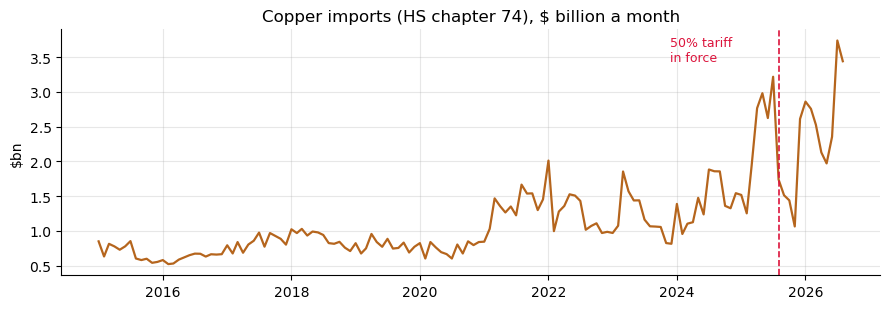

In [3]:
def chapter_series(ch, col="value"):
    s = cm[cm.chapter==ch].set_index("ym")[col].sort_index()
    return s[s>0]

fig, ax = plt.subplots()
s = chapter_series("74")/1e9
ax.plot(s.index, s.values, lw=1.6, color="#b5651d")
ax.axvline(pd.Timestamp("2025-08-01"), color="crimson", ls="--", lw=1.2)
ax.annotate("50% tariff\nin force", (pd.Timestamp("2025-08-01"), s.max()*.92),
            xytext=(-78,0), textcoords="offset points", color="crimson", fontsize=9)
ax.set_title("Copper imports (HS chapter 74), $ billion a month")
ax.set_ylabel("$bn"); plt.tight_layout(); plt.show()

There is a clear climb before the red line and a drop after it. That is the pattern we are
after.

But a single chart like this is not evidence. Imports move for all sorts of reasons: prices,
seasons, the business cycle. Before calling this a tariff effect we need to say what copper
imports would have done anyway.

## 3. How do we know what counts as normal?

We build an expected line from the years before the tariff and carry it forward, then draw a
band around it wide enough to cover the ordinary month-to-month wobble. Anything outside the
band is unusual.

The expected line uses only data from before the event, so the tariff cannot leak into it.

In [4]:
def expected(s, cut="2024-12"):
    """Average seasonal shape and recent trend from before `cut`, carried forward."""
    pre = np.log(s[:cut])
    month_effect = pre.groupby(pre.index.month).mean() - pre.mean()
    t = np.arange(len(pre))
    slope, intercept = np.polyfit(t[-36:], pre.values[-36:], 1)
    steps = np.arange(len(s)) - (len(pre)-1)
    line = pre.values[-1] + slope*steps
    pred = np.exp(line + s.index.month.map(month_effect).values)
    resid = pre.values - (intercept + slope*t) - pre.index.month.map(month_effect).values
    return pd.Series(pred, index=s.index), float(np.std(resid, ddof=1))

for ch, name in [("74","copper"), ("76","aluminium")]:
    s = chapter_series(ch)
    pred, sd = expected(s)
    peak = (s/pred - 1).loc["2025-01":"2025-08"].max()
    print(f"{name:<10} peak {peak:+.0%} above normal in 2025   normal wobble is +/-{1.96*sd:.0%}")

copper     peak +89% above normal in 2025   normal wobble is +/-50%
aluminium  peak +26% above normal in 2025   normal wobble is +/-100%


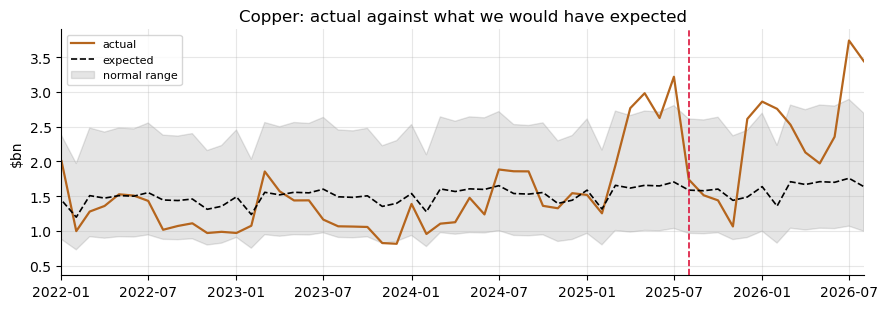

In [5]:
fig, ax = plt.subplots()
s = chapter_series("74")/1e9
pred, sd = expected(chapter_series("74")); pred = pred/1e9
ax.plot(s.index, s.values, lw=1.6, color="#b5651d", label="actual")
ax.plot(pred.index, pred.values, lw=1.2, color="k", ls="--", label="expected")
ax.fill_between(pred.index, pred*np.exp(-1.96*sd), pred*np.exp(1.96*sd),
                color="k", alpha=.10, label="normal range")
ax.axvline(pd.Timestamp("2025-08-01"), color="crimson", ls="--", lw=1.2)
ax.set_xlim(pd.Timestamp("2022-01-01"), s.index.max())
ax.set_title("Copper: actual against what we would have expected")
ax.set_ylabel("$bn"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Copper went far outside its normal range in 2025. Aluminium did not, and that is the point of
having a band: aluminium peaked 26% above normal, but its ordinary month-to-month swing is
about 100%, so 26% is unremarkable for it. Same tariff year, and the test still says no.

**Be careful with this chart.** The expected line is a description, not proof. We tested it by
pretending tariffs happened on dates when nothing happened, and the line drifts enough to
produce fake surges. It is fine for looking at the data, which is what we are doing here, and
not good enough to measure an effect. Section 6 is about the fix.

## 4. Which products did this happen to?

Running the same comparison across all 98 chapters, rather than the ones we already suspected.
The last column is the chapter's 2024 size in billions, which is there to stop us reading much
into a chapter that barely trades.

In [6]:
rows=[]
for ch in sorted(cm.chapter.unique()):
    s = chapter_series(ch)
    if len(s) < 100 or s[:"2024-12"].min() <= 0: continue
    pred, sd = expected(s)
    dev = (s/pred - 1).loc["2025-01":"2025-08"]
    if dev.empty or sd == 0: continue
    rows.append(dict(chapter=ch, peak=dev.max(), band=1.96*sd,
                     ratio=dev.max()/(1.96*sd), size=s.loc["2024"].sum()/1e9))
r = pd.DataFrame(rows).sort_values("ratio", ascending=False)
NAMES={"74":"copper","76":"aluminium","80":"tin","78":"lead","18":"cocoa","98":"US goods returned",
       "72":"iron & steel","73":"steel articles","40":"rubber","87":"vehicles","30":"pharma",
       "29":"organic chems","71":"gold & gems","89":"ships","97":"works of art",
       "91":"clocks","50":"silk","84":"machinery","85":"electrical"}
r["name"]=r.chapter.map(NAMES).fillna("")
print("chapters furthest outside their own normal range, 2025\n")
print(r.head(10)[["chapter","name","peak","band","ratio","size"]]
        .to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

chapters furthest outside their own normal range, 2025

chapter          name  peak  band  ratio   size
     29 organic chems  2.75  0.45   6.06  69.67
     30        pharma  0.57  0.20   2.86 209.81
     89         ships  1.73  0.76   2.28   3.74
     71   gold & gems  1.48  0.68   2.18  89.07
     97  works of art  1.46  0.77   1.90   8.81
     91        clocks  0.87  0.46   1.87   7.58
     74        copper  0.89  0.50   1.79  17.10
     50          silk  0.79  0.46   1.70   0.06
     84     machinery  0.22  0.16   1.38 520.62
     18         cocoa  0.82  0.60   1.37   8.09


**Some of these are tariff stories and some are not, and the detector cannot tell them apart.**

Plausible ones: organic chemicals and pharmaceuticals were both under open tariff threat during
2025, and gold and gems surged as metal was moved into US vaults ahead of expected duties.

Not tariff stories: silk is a $60 million chapter, so almost any month looks extreme next to its
own history. Works of art and clocks are small and lumpy for reasons that have nothing to do
with trade policy. Cocoa is the clearest trap of all, sitting high because cocoa prices roughly
tripled after bad West African harvests. We measure in dollars, so a price spike reads as a
volume surge.

So the detector finds unusual months. It does not know why they are unusual. Something has to
connect an unusual month to an actual tariff, which is the next section.

## 5. What tariffs do we have?

We searched the Federal Register, the government's daily record of official actions, and
classified every document that announced a tariff.

In [7]:
e = pd.read_csv("events/tariff_events.csv", parse_dates=["announcement_date"])
d = pd.read_csv("events/tariff_events_dates.csv", parse_dates=["announcement_date","effective_date"])
print(f"documents reviewed   2,792")
print(f"actual tariff actions  {len(e)}")
print()
print("by legal authority:")
print(e.authority.value_counts().to_string())
print()
w = d.window_days.dropna()
print(f"days between announcement and start date: median {w.median():.0f}, "
      f"{(w>=21).sum()} actions gave 3 weeks or more")

documents reviewed   2,792
actual tariff actions  134

by legal authority:
authority
SECTION_232    47
SECTION_301    30
UNKNOWN        28
IEEPA          27
SECTION_201     1
OTHER           1

days between announcement and start date: median 8, 30 actions gave 3 weeks or more


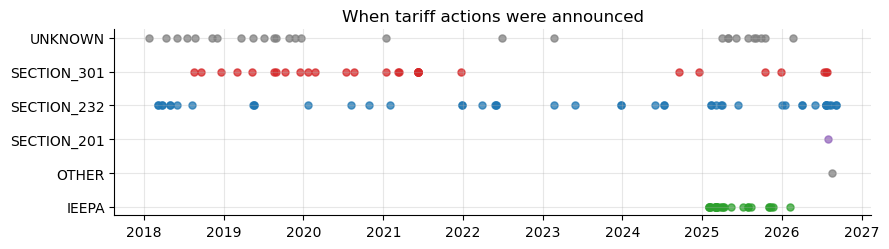

In [8]:
fig, ax = plt.subplots(figsize=(9,2.6))
cols = {"SECTION_232":"#1f77b4","SECTION_301":"#d62728","IEEPA":"#2ca02c","SECTION_201":"#9467bd"}
for a, g in e.groupby("authority"):
    ax.scatter(g.announcement_date, [a]*len(g), s=26, alpha=.75,
               color=cols.get(a,"grey"))
ax.set_title("When tariff actions were announced"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Two waves: 2018-2019, and a much bigger one in 2025.

## 6. The problem we had to solve first

A tariff action does not say "chapter 74". It points at a list of 8-digit product codes, often
published in a separate legal notice. Until we read those lists, the only thing we could do was
treat a whole chapter as tariffed whenever an action touched anything inside it.

That turns out to be badly wrong, and this is the most important chart in the notebook.

tariff actions matched to their actual product lists: 162
distinct 8-digit product codes named:                 9,083

share of a chapter's import value that an action actually covers:
   median 5.4%
   a quarter of actions cover less than 0.4%


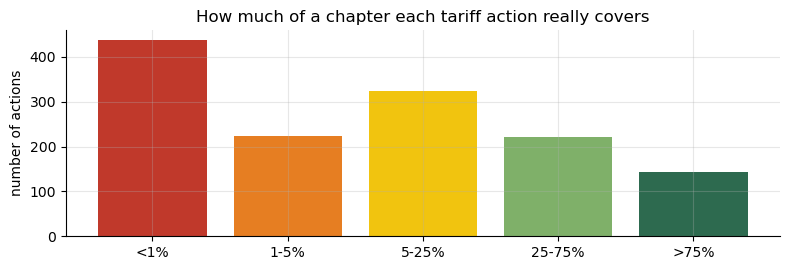

In [9]:
sh = pd.read_csv("coverage/coverage_share.csv", dtype={"chapter":str})
print(f"tariff actions matched to their actual product lists: {sh.htsno.nunique():,}")
print(f"distinct 8-digit product codes named:                 "
      f"{pd.read_csv('coverage/product_lines.csv', dtype=str).hs8.nunique():,}")
print()
print(f"share of a chapter's import value that an action actually covers:")
print(f"   median {sh.share.median():.1%}")
print(f"   a quarter of actions cover less than {sh.share.quantile(.25):.1%}")

fig, ax = plt.subplots(figsize=(8,2.8))
bands = pd.cut(sh.share,[-.001,.01,.05,.25,.75,1.001],
               labels=["<1%","1-5%","5-25%","25-75%",">75%"])
v = bands.value_counts().reindex(["<1%","1-5%","5-25%","25-75%",">75%"])
ax.bar(v.index, v.values, color=["#c0392b","#e67e22","#f1c40f","#7fb069","#2d6a4f"])
ax.set_title("How much of a chapter each tariff action really covers")
ax.set_ylabel("number of actions"); plt.tight_layout(); plt.show()

**The typical tariff action covers about 5% of its chapter's value. A third cover under 1%.**

So treating the whole chapter as tariffed means roughly 95% of what we were measuring was trade
the tariff never touched. Any real reaction in the 5% gets averaged away by the 95% that did
nothing. That is exactly what happened: our first attempt at measuring an effect found nothing,
and this is why.

The fix is to work at the 8-digit level, where the tariff either names a product or it does not.
That is what the rest of the project is built on.

**Where this leaves us.**

- We have 140 months of imports at the exact level tariffs are written, checked against published
  totals.
- We can find months that are unusual for a product, and we know the detector cannot tell a
  tariff from a price shock on its own.
- We have 134 tariff actions with corrected dates, and we now know which products each one names.
- We know the measurement trap that made the first attempt fail, and we have measured how big
  it is.